# CIE-2 Activity 2: Binary Classification with Logistic Regression — Loan Approval

**Student roll number:** AD3125 
**Subject:** Regression and Classification Algorithms (RCA), T.Y. B.Tech AI & DS, Zeal College of Engineering and Research 
**Unit:** Unit II — Classification and Logistic Regression

**Dataset source:** taweilo, *Loan Approval Classification Dataset*, Kaggle (synthetic data for binary classification). https://www.kaggle.com/datasets/taweilo/loan-approval-classification-data 
**File:** `loan_data.csv`, 45,000 rows, 14 columns. The source describes the data as synthetic, so results describe this dataset and may not transfer to real lending.

---

## Professional framing (Thinking cycle)

| Stage | My answer |
|---|---|
| **Frame the problem** | A bank's credit team wants to know which loan applications the model would approve. The model supports the decision and does not replace human underwriting. |
| **Positive class** | `loan_status = 1` means **approved**. `loan_status = 0` means **rejected**. The source defines 1 as approved. |
| **Costs of error** | A **false positive** approves an applicant who should be rejected, which creates credit loss. A **false negative** rejects an applicant who would have repaid, which loses business and is unfair to that applicant. |
| **Success metric** | ROC-AUC for ranking quality, plus precision and recall at a chosen threshold. Accuracy is misleading here because 77.8% of applications are rejected. |
| **Baseline** | Always predict "rejected" (the majority class). It scores 77.8% accuracy, and recall of 0% for approved applicants. |

## 1. Setup and reproducibility

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    roc_curve, precision_recall_curve
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("pandas", pd.__version__, "| numpy", np.__version__, "| sklearn", sklearn.__version__)

pandas 3.0.6 | numpy 2.5.4 | sklearn 1.9.1


## 2. Load and inspect the data

In [2]:
df = pd.read_csv("loan_data.csv")
print("Shape:", df.shape)
display(df.head())
df.info()
display(df.describe().T)

Shape: (45000, 14)


,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1


<class 'pandas.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  float64
 1   person_gender                   45000 non-null  str    
 2   person_education                45000 non-null  str    
 3   person_income                   45000 non-null  float64
 4   person_emp_exp                  45000 non-null  int64  
 5   person_home_ownership           45000 non-null  str    
 6   loan_amnt                       45000 non-null  float64
 7   loan_intent                     45000 non-null  str    
 8   loan_int_rate                   45000 non-null  float64
 9   loan_percent_income             45000 non-null  float64
 10  cb_person_cred_hist_length      45000 non-null  float64
 11  credit_score                    45000 non-null  int64  
 12  previous_loan_defaults_on_file  45000 non-n

,count,mean,std,min,25%,50%,75%,max
person_age,45000.0,27.764178,6.045108,20.00,24.00,26.00,30.00,144.00
person_income,45000.0,80319.053222,80422.498632,8000.00,47204.00,67048.00,95789.25,7200766.00
person_emp_exp,45000.0,5.410333,6.063532,0.00,1.00,4.00,8.00,125.00
loan_amnt,45000.0,9583.157556,6314.886691,500.00,5000.00,8000.00,12237.25,35000.00
loan_int_rate,45000.0,11.006606,2.978808,5.42,8.59,11.01,12.99,20.00
loan_percent_income,45000.0,0.139725,0.087212,0.00,0.07,0.12,0.19,0.66
cb_person_cred_hist_length,45000.0,5.867489,3.879702,2.00,3.00,4.00,8.00,30.00
credit_score,45000.0,632.608756,50.435865,390.00,601.00,640.00,670.00,850.00
loan_status,45000.0,0.222222,0.415744,0.00,0.00,0.00,0.00,1.00


## 3. Data quality checks and cleaning

**Decision log:**
- **Missing values and duplicates:** none found, so no imputation was needed.
- **Implausible ages:** 7 applicants are over 100 years old. These are almost certainly entry errors, so I removed them. Employment experience is always consistent with age, so no further filtering was needed.
- **High incomes and loan amounts:** kept. They are plausible for some applicants and removing them would hide real customers.

In [3]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

implausible = df["person_age"] > 100
print("Applicants aged over 100 (removed):", implausible.sum())
df = df[~implausible].reset_index(drop=True)
print("Cleaned shape:", df.shape)

Missing values: 0
Duplicate rows: 0
Applicants aged over 100 (removed): 7
Cleaned shape: (44993, 14)


## 4. Dataset understanding and class balance

Each row is one loan application. The target is `loan_status`: 1 = approved, 0 = rejected. The bar chart shows how many applications fall in each class.

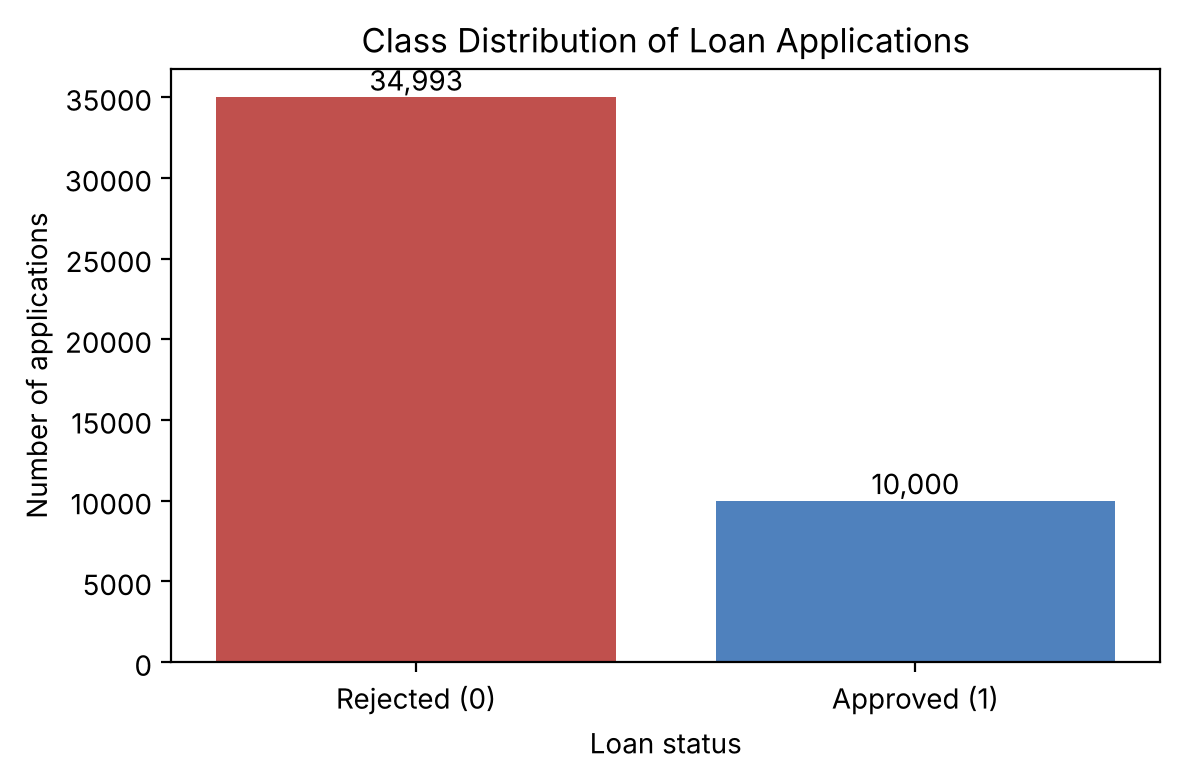

{0: 0.7777, 1: 0.2223}


In [4]:
counts = df["loan_status"].value_counts().sort_index()
labels = ["Rejected (0)", "Approved (1)"]

plt.figure(figsize=(6, 4))
bars = plt.bar(labels, counts.values, color=["#c0504d", "#4f81bd"])
plt.bar_label(bars, labels=[f"{v:,}" for v in counts.values])
plt.title("Class Distribution of Loan Applications")
plt.xlabel("Loan status")
plt.ylabel("Number of applications")
plt.tight_layout(); plt.show()

print((counts / counts.sum()).round(4).to_dict())

**Observation:** The classes are imbalanced. About 77.8% of applications are rejected and 22.2% are approved. A model that always says "rejected" would score 77.8% accuracy while approving no one. This is why accuracy is not used as the main metric.

## 5. Prepare the features

**Feature decisions:**
- **Identifiers:** none in this dataset, so none were dropped.
- **Target leakage:** `loan_int_rate` is the interest rate set after the lending decision, so it is excluded. Using it would let the model "see" the outcome.
- **Binary column:** `previous_loan_defaults_on_file` (Yes/No) is converted to 1/0.
- **Categorical columns:** gender, education, home ownership, and loan intent are one-hot encoded, with one category dropped as the reference to avoid redundant columns.
- **Scaling:** numeric features are standardised inside a pipeline, so the scaler is fitted on training data only.

In [5]:
TARGET = "loan_status"
EXCLUDED = ["loan_int_rate"]   # set after the decision, so it would leak the outcome

df_model = df.copy()
df_model["previous_loan_defaults_on_file"] = (df_model["previous_loan_defaults_on_file"] == "Yes").astype(int)

df_model = pd.get_dummies(
    df_model,
    columns=["person_gender", "person_education", "person_home_ownership", "loan_intent"],
    drop_first=True, dtype=int
)

X = df_model.drop(columns=[TARGET] + EXCLUDED)
y = df_model[TARGET]
print("Feature matrix X:", X.shape, "| target y:", y.shape)
print("Features:", X.columns.tolist())

Feature matrix X: (44993, 21) | target y: (44993,)
Features: ['person_age', 'person_income', 'person_emp_exp', 'loan_amnt', 'loan_percent_income', 'cb_person_cred_hist_length', 'credit_score', 'previous_loan_defaults_on_file', 'person_gender_male', 'person_education_Bachelor', 'person_education_Doctorate', 'person_education_High School', 'person_education_Master', 'person_home_ownership_OTHER', 'person_home_ownership_OWN', 'person_home_ownership_RENT', 'loan_intent_EDUCATION', 'loan_intent_HOMEIMPROVEMENT', 'loan_intent_MEDICAL', 'loan_intent_PERSONAL', 'loan_intent_VENTURE']


## 6. Stratified train / test split

An 80:20 split, stratified on `loan_status`, keeps the same approval rate in both sets. The test set is used only for final evaluation.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train rows:", len(X_train), "| class counts:", y_train.value_counts().sort_index().to_dict())
print("Test rows: ", len(X_test), "| class counts:", y_test.value_counts().sort_index().to_dict())

Train rows: 35994 | class counts: {0: 27994, 1: 8000}
Test rows:  8999 | class counts: {0: 6999, 1: 2000}


## 7. Why not Linear Regression, and the sigmoid function

**Why not Linear Regression?** Linear regression predicts any number, so it can output values below 0 or above 1. Those outputs cannot be read as probabilities. Its errors also do not fit a 0/1 outcome, so the fitted line is a poor description of the data.

**The sigmoid function** squashes any real score `z` into the range 0 to 1:

σ(z) = 1 / (1 + e^(−z))

Logistic regression computes `z` as a weighted sum of the features and passes it through the sigmoid to get a probability of approval. A **decision threshold** (0.5 by default) turns that probability into a yes/no label.

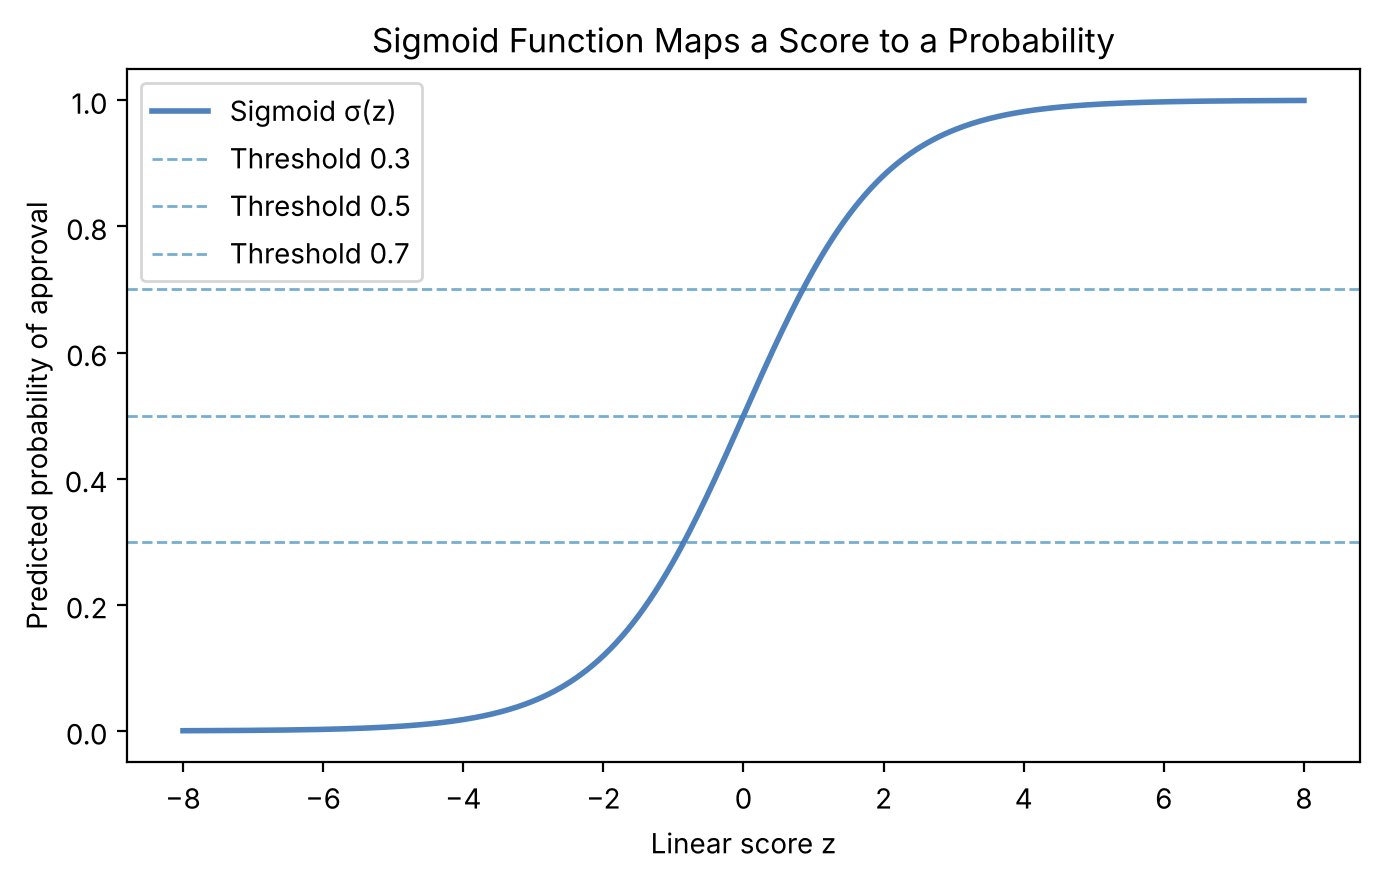

In [7]:
z = np.linspace(-8, 8, 400)
sigmoid = 1 / (1 + np.exp(-z))

plt.figure(figsize=(7, 4.5))
plt.plot(z, sigmoid, color="#4f81bd", lw=2, label="Sigmoid σ(z)")
for t in [0.3, 0.5, 0.7]:
    plt.axhline(t, linestyle="--", lw=1, alpha=0.6, label=f"Threshold {t}")
plt.title("Sigmoid Function Maps a Score to a Probability")
plt.xlabel("Linear score z")
plt.ylabel("Predicted probability of approval")
plt.legend(); plt.tight_layout(); plt.show()

## 8. Train Logistic Regression

The model is trained on the training set only. The pipeline standardises the features and then fits logistic regression. I used the default L2 penalty with a fixed seed and enough iterations to converge.

In [8]:
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
)
model.fit(X_train, y_train)

coefs = pd.Series(model[-1].coef_[0], index=X.columns, name="Coefficient (scaled)")
print("Intercept:", round(float(model[-1].intercept_[0]), 4))
display(coefs.sort_values(key=abs, ascending=False).round(3).to_frame())

Intercept: -5.0049


,Coefficient (scaled)
previous_loan_defaults_on_file,-4.472
loan_percent_income,1.178
person_home_ownership_RENT,0.458
loan_intent_VENTURE,-0.454
credit_score,-0.450
loan_amnt,-0.404
loan_intent_EDUCATION,-0.388
person_home_ownership_OWN,-0.291
loan_intent_PERSONAL,-0.265
loan_intent_MEDICAL,-0.084


**Coefficient interpretation** (coefficients are on standardised features, so their sizes are comparable):
- **`previous_loan_defaults_on_file` (strongly negative):** applicants with a past default are much less likely to be approved. This is the largest effect.
- **`loan_percent_income` (positive):** a higher loan-to-income ratio goes with a *higher* approval probability. This is the opposite of what a lender would normally expect, so I checked it below and flag it as a red flag in the data rather than a finding.
- **Loan amount and loan purpose (negative):** larger loans and some purposes such as venture loans are associated with lower approval.
- **Home ownership:** renters are somewhat more likely to be approved than owners in this data.
- **Credit score (moderately negative, -0.45):** a higher credit score is associated with *lower* approval odds. This is counterintuitive, so like the loan-to-income ratio it should be treated as a data artefact to investigate, not a business rule.

A positive coefficient raises the odds of approval, a negative one lowers them. These are associations learned from this synthetic dataset, not causal effects.

## 9. Predicted probabilities and labels on the test set

In [9]:
proba = model.predict_proba(X_test)[:, 1]
pred_05 = (proba >= 0.5).astype(int)

sample = pd.DataFrame({
    "Actual label": y_test.values[:10],
    "Predicted probability (approved)": proba[:10].round(3),
    "Predicted label (threshold 0.5)": pred_05[:10]
})
display(sample)

,Actual label,Predicted probability (approved),Predicted label (threshold 0.5)
0,0,0.485,0
1,0,0.000,0
2,0,0.000,0
3,0,0.000,0
4,0,0.000,0
5,0,0.256,0
6,1,0.937,1
7,0,0.294,0
8,0,0.074,0
9,0,0.000,0


## 10. Effect of the decision threshold on the number of approvals

In [10]:
rows = []
for t in [0.3, 0.5, 0.7]:
    rows.append({"Threshold": t, "Predicted approved": int((proba >= t).sum()),
                 "Share of test set predicted approved": round((proba >= t).mean(), 3)})
display(pd.DataFrame(rows).set_index("Threshold"))

,Predicted approved,Share of test set predicted approved
Threshold,,
0.3,2866,0.318
0.5,1818,0.202
0.7,1070,0.119


**Observation:** Lowering the threshold to 0.3 approves many more applicants, while raising it to 0.7 approves far fewer. The true number of approved applicants in the test set is 2,000. The threshold therefore controls how many approvals the bank makes, and that trade-off is examined in Section 12.

## 11. Classification evaluation on the test set

**Positive class = approved (1).** TP = approved and correctly predicted, FP = rejected but predicted approved, FN = approved but predicted rejected, TN = rejected and correctly predicted.

| Metric | Formula | Meaning here |
|---|---|---|
| Accuracy | (TP + TN) / (TP + TN + FP + FN) | Share of all correct decisions. Misleading when classes are imbalanced. |
| Precision | TP / (TP + FP) | Of applicants the model approves, how many really should be approved. |
| Recall (sensitivity) | TP / (TP + FN) | Of applicants who should be approved, how many the model approves. |
| Specificity | TN / (TN + FP) | Of applicants who should be rejected, how many the model rejects. |
| F1-score | 2 × (Precision × Recall) / (Precision + Recall) | Balance between precision and recall. |
| ROC-AUC | Area under the ROC curve | Chance that a random approved applicant gets a higher score than a random rejected one. 0.5 = chance, 1.0 = perfect. |

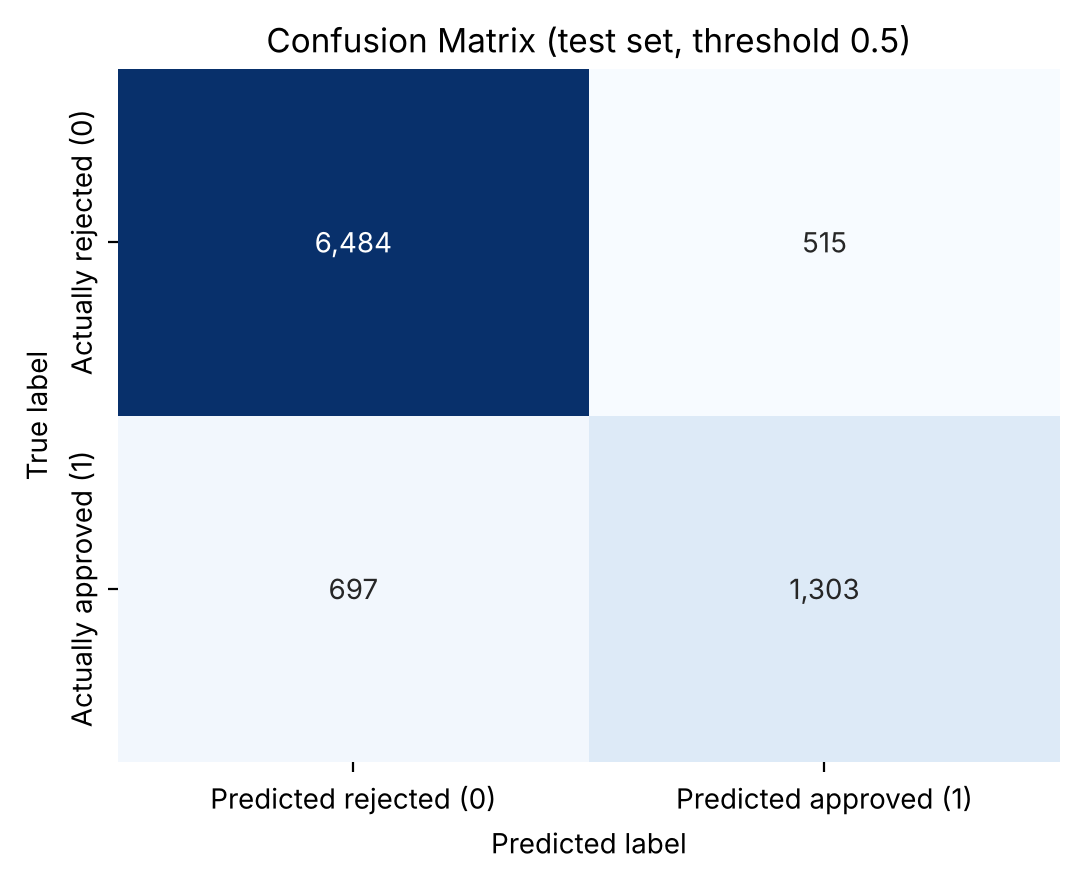

TP = 1,303 | FP = 515 | FN = 697 | TN = 6,484


In [11]:
tn, fp, fn, tp = confusion_matrix(y_test, pred_05).ravel()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
cm = np.array([[tn, fp], [fn, tp]])
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Predicted rejected (0)", "Predicted approved (1)"],
            yticklabels=["Actually rejected (0)", "Actually approved (1)"])
ax.set_title("Confusion Matrix (test set, threshold 0.5)")
ax.set_xlabel("Predicted label"); ax.set_ylabel("True label")
plt.tight_layout(); plt.show()

print(f"TP = {tp:,} | FP = {fp:,} | FN = {fn:,} | TN = {tn:,}")

**Confusion matrix explained:**
- **TP (1,303):** approved applicants the model correctly approved.
- **FP (515):** rejected applicants the model wrongly approved. These are the credit-loss risk.
- **FN (697):** approved applicants the model wrongly rejected. These are lost customers.
- **TN (6,484):** rejected applicants the model correctly rejected.

In [12]:
metrics_05 = {
    "Accuracy": accuracy_score(y_test, pred_05),
    "Precision": precision_score(y_test, pred_05),
    "Recall (sensitivity)": recall_score(y_test, pred_05),
    "Specificity": tn / (tn + fp),
    "F1-score": f1_score(y_test, pred_05),
    "ROC-AUC": roc_auc_score(y_test, proba),
}
results_table = pd.Series(metrics_05, name="Test-set result (threshold 0.5)").round(4)
display(results_table.to_frame())

print("\nFull classification report:")
print(classification_report(y_test, pred_05, target_names=["Rejected (0)", "Approved (1)"], digits=3))

,Test-set result (threshold 0.5)
Accuracy,0.8653
Precision,0.7167
Recall (sensitivity),0.6515
Specificity,0.9264
F1-score,0.6826
ROC-AUC,0.9297



Full classification report:
              precision    recall  f1-score   support

Rejected (0)      0.903     0.926     0.915      6999
Approved (1)      0.717     0.651     0.683      2000

    accuracy                          0.865      8999
   macro avg      0.810     0.789     0.799      8999
weighted avg      0.862     0.865     0.863      8999



**Interpretation:**
- **Accuracy 86.5%** looks strong, but the majority-class baseline already scores 77.8%, so the model adds about 9 points of accuracy.
- **Precision 71.7%:** about 7 in 10 approvals are correct.
- **Recall 65.2%:** the model finds about two thirds of the applicants who should be approved.
- **Specificity 92.6%:** the model correctly rejects over 9 in 10 rejected applicants.
- **ROC-AUC 0.93:** a randomly chosen approved applicant is ranked above a randomly chosen rejected one about 93% of the time. This is strong ranking ability, but it depends heavily on the past-default feature (see Section 13).

### Majority-class baseline comparison
A model that always predicts "rejected" gets 77.8% accuracy with zero precision and zero recall for approvals. Accuracy alone would make this look reasonable, which is why the precision, recall, and AUC results above matter more.

In [13]:
baseline_pred = np.zeros(len(y_test), dtype=int)
baseline = {
    "Accuracy": accuracy_score(y_test, baseline_pred),
    "Precision": precision_score(y_test, baseline_pred, zero_division=0),
    "Recall": recall_score(y_test, baseline_pred, zero_division=0),
    "F1-score": f1_score(y_test, baseline_pred, zero_division=0),
}
comparison = pd.DataFrame({"Majority-class baseline": baseline,
                           "Logistic regression (0.5)": {
                               "Accuracy": metrics_05["Accuracy"],
                               "Precision": metrics_05["Precision"],
                               "Recall": metrics_05["Recall (sensitivity)"],
                               "F1-score": metrics_05["F1-score"]}})
display(comparison.round(4))

,Majority-class baseline,Logistic regression (0.5)
Accuracy,0.7778,0.8653
Precision,0.0000,0.7167
Recall,0.0000,0.6515
F1-score,0.0000,0.6826


### ROC curve and precision-recall curve

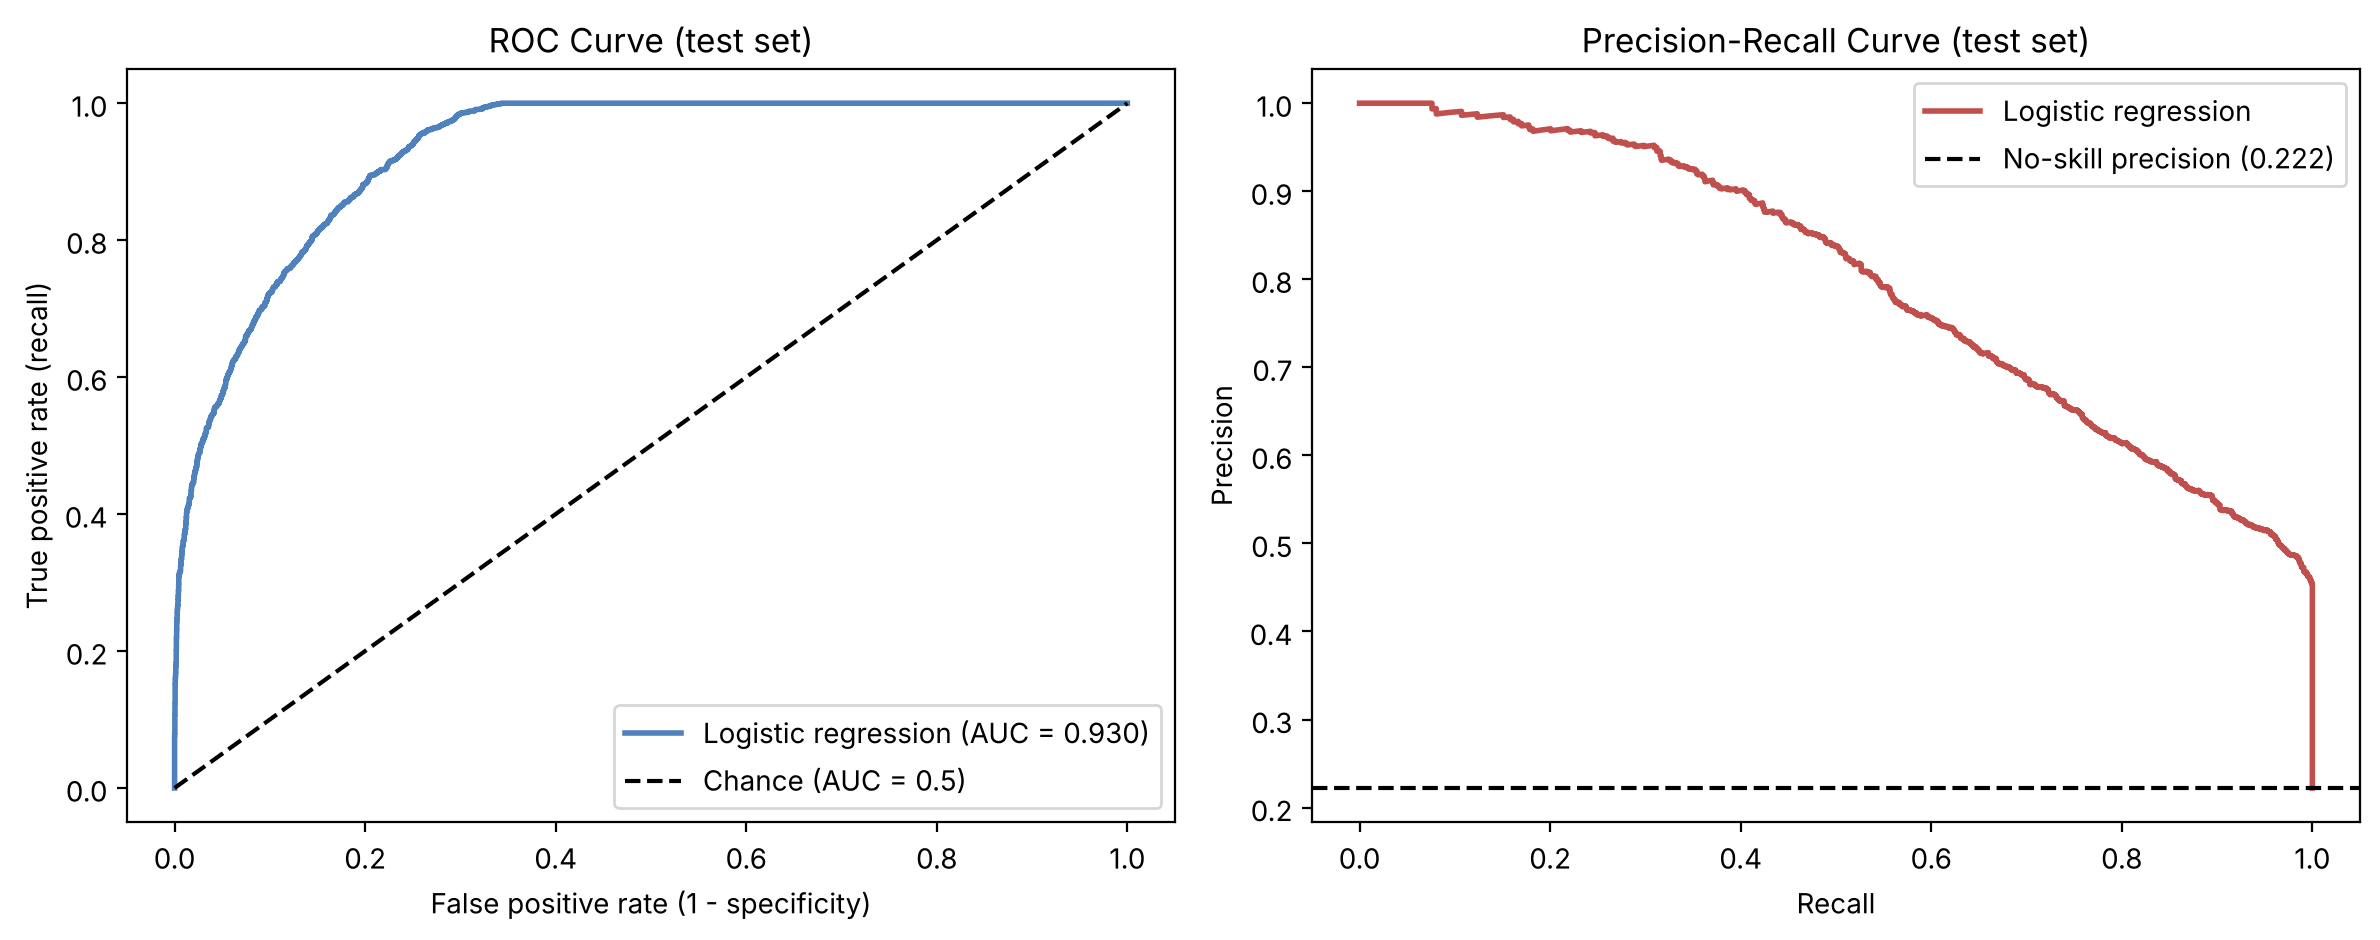

In [14]:
fpr, tpr, _ = roc_curve(y_test, proba)
prec_curve, rec_curve, _ = precision_recall_curve(y_test, proba)
base_rate = y_test.mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].plot(fpr, tpr, color="#4f81bd", lw=2, label=f"Logistic regression (AUC = {metrics_05['ROC-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="Chance (AUC = 0.5)")
axes[0].set(title="ROC Curve (test set)", xlabel="False positive rate (1 - specificity)", ylabel="True positive rate (recall)")
axes[0].legend()

axes[1].plot(rec_curve, prec_curve, color="#c0504d", lw=2, label="Logistic regression")
axes[1].axhline(base_rate, color="k", linestyle="--", label=f"No-skill precision ({base_rate:.3f})")
axes[1].set(title="Precision-Recall Curve (test set)", xlabel="Recall", ylabel="Precision")
axes[1].legend()
plt.tight_layout(); plt.show()

**Observation:** The ROC curve bows well above the chance diagonal, which matches the AUC of 0.93. The precision-recall curve is more informative for imbalanced data: precision stays well above the no-skill line (the approval rate of 22%) across much of the recall range, so the model is useful beyond the base rate.

## 12. Threshold comparison and the precision-recall trade-off

In [15]:
rows = []
for t in [0.3, 0.5, 0.7]:
    p_t = (proba >= t).astype(int)
    rows.append({
        "Threshold": t,
        "Predicted approved": int(p_t.sum()),
        "Accuracy": accuracy_score(y_test, p_t),
        "Precision": precision_score(y_test, p_t, zero_division=0),
        "Recall": recall_score(y_test, p_t, zero_division=0),
        "F1-score": f1_score(y_test, p_t, zero_division=0),
    })
threshold_table = pd.DataFrame(rows).set_index("Threshold").round(4)
display(threshold_table)

,Predicted approved,Accuracy,Precision,Recall,F1-score
Threshold,,,,,
0.3,2866,0.8333,0.5872,0.8415,0.6917
0.5,1818,0.8653,0.7167,0.6515,0.6826
0.7,1070,0.8635,0.8607,0.4605,0.6000


**Trade-off:**
- **Threshold 0.3:** recall rises to 84%, so most true approvals are found, but precision falls to 59%. About 4 in 10 approvals would be wrong, and more risky loans would be granted.
- **Threshold 0.5:** a balanced compromise. Precision is 72% and recall 65%.
- **Threshold 0.7:** precision rises to 86%, so approvals are very reliable, but recall falls to 46%. More than half of the applicants who should be approved would be rejected.

**Which error is costlier?** For a lender, a false positive means lending to someone who may not repay, which is a direct financial loss. A false negative loses a customer, which is also a cost but a smaller one per case. I would therefore **recommend threshold 0.5** as the default, since it keeps precision above 70% without rejecting too many good applicants. A lender with a low risk appetite could move to 0.6 or 0.7. The final choice is a business decision, and the model should not set it alone.

## 13. Leakage and sensitivity check: the past-default feature

`previous_loan_defaults_on_file` separates the classes almost perfectly in this dataset: in the full data, every applicant with a past default was rejected. A score that is too good to be true is a warning sign. To check how much the model depends on this one column, I retrain the same pipeline without it.

In [16]:
X_train_nd = X_train.drop(columns=["previous_loan_defaults_on_file"])
X_test_nd = X_test.drop(columns=["previous_loan_defaults_on_file"])

model_nd = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
model_nd.fit(X_train_nd, y_train)
proba_nd = model_nd.predict_proba(X_test_nd)[:, 1]
pred_nd = (proba_nd >= 0.5).astype(int)

tn2, fp2, fn2, tp2 = confusion_matrix(y_test, pred_nd).ravel()
compare = pd.DataFrame({
    "With past-default feature": {
        "ROC-AUC": roc_auc_score(y_test, proba),
        "Precision (0.5)": precision_score(y_test, pred_05),
        "Recall (0.5)": recall_score(y_test, pred_05),
        "Accuracy (0.5)": accuracy_score(y_test, pred_05)},
    "Without past-default feature": {
        "ROC-AUC": roc_auc_score(y_test, proba_nd),
        "Precision (0.5)": precision_score(y_test, pred_nd),
        "Recall (0.5)": recall_score(y_test, pred_nd),
        "Accuracy (0.5)": accuracy_score(y_test, pred_nd)},
}).round(4)
display(compare)

,With past-default feature,Without past-default feature
ROC-AUC,0.9297,0.7850
Precision (0.5),0.7167,0.7417
Recall (0.5),0.6515,0.4020
Accuracy (0.5),0.8653,0.8360


**Interpretation:** Removing the past-default feature drops ROC-AUC from 0.93 to about 0.79 and recall from 65% to 40%. The model without it is still useful, so the other applicant features carry real signal. But most of the headline performance comes from one column that may be an artefact of how this synthetic dataset was generated.

**Recommendation:** Report the model with the feature for the primary results, since a real lender would have this information. Do not present the 0.93 AUC as proof that the model is reliable on real applicants. Validate on real data before any decision use.

## 14. Training versus test performance (overfitting check)

In [17]:
train_pred = model.predict(X_train)
train_proba = model.predict_proba(X_train)[:, 1]
overfit = pd.DataFrame({
    "Train": {"Accuracy": accuracy_score(y_train, train_pred),
              "ROC-AUC": roc_auc_score(y_train, train_proba)},
    "Test": {"Accuracy": accuracy_score(y_test, pred_05),
             "ROC-AUC": roc_auc_score(y_test, proba)}
}).round(4)
display(overfit)

,Train,Test
Accuracy,0.8696,0.8653
ROC-AUC,0.9342,0.9297


**Observation:** Train and test scores are close (train AUC 0.934 vs test 0.930; accuracy 0.870 vs 0.865). The gap is small, so the model is not overfitting. It is also not underfitting, since the scores are well above the baseline.

## 15. Decision behaviour: probability against one feature

I plot the predicted approval probability against `loan_percent_income`, coloured by the true outcome. This shows how the model separates the two classes along that feature. Because past defaults dominate, the separation along this feature is partial rather than clean.

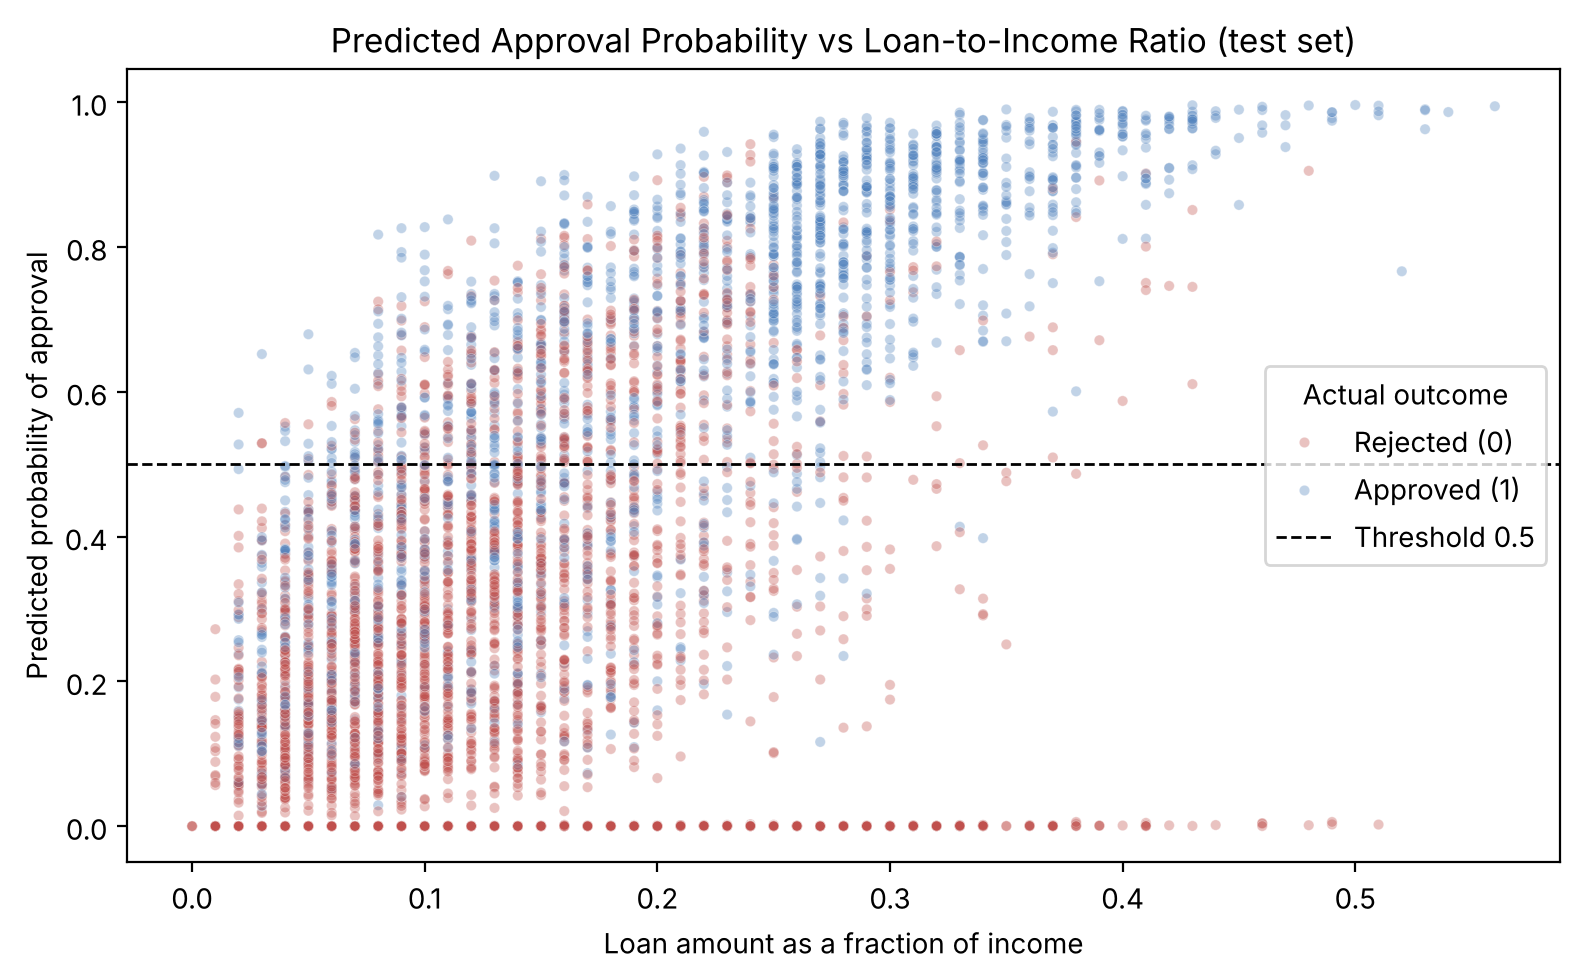

In [18]:
plot_df = pd.DataFrame({
    "loan_percent_income": X_test["loan_percent_income"].values,
    "Predicted probability": proba,
    "Actual outcome": np.where(y_test.values == 1, "Approved (1)", "Rejected (0)")
})

plt.figure(figsize=(8, 5))
sns.scatterplot(data=plot_df, x="loan_percent_income", y="Predicted probability",
                hue="Actual outcome", alpha=0.35, s=14, palette={"Approved (1)": "#4f81bd", "Rejected (0)": "#c0504d"})
plt.axhline(0.5, color="k", linestyle="--", lw=1, label="Threshold 0.5")
plt.title("Predicted Approval Probability vs Loan-to-Income Ratio (test set)")
plt.xlabel("Loan amount as a fraction of income")
plt.ylabel("Predicted probability of approval")
plt.legend(title="Actual outcome"); plt.tight_layout(); plt.show()

## 16. Classify a new applicant

I use a reasonable new applicant with values inside the training range, and apply the same preprocessing by building the row in the same column order as `X`.

In [19]:
new_applicant = X.median().to_frame().T
values = {
    "person_income": 60000, "loan_amnt": 15000, "loan_percent_income": 0.25,
    "credit_score": 700, "person_age": 30, "person_emp_exp": 5,
    "cb_person_cred_hist_length": 6, "previous_loan_defaults_on_file": 0,
    "person_home_ownership_RENT": 1, "loan_intent_EDUCATION": 1,
}
for k, v in values.items():
    new_applicant[k] = v
new_applicant = new_applicant[X.columns]

new_proba = model.predict_proba(new_applicant)[0, 1]
new_label = int(new_proba >= 0.5)
print("Predicted probability of approval: %.3f" % new_proba)
print("Predicted label at threshold 0.5:", "Approved (1)" if new_label else "Rejected (0)")

Predicted probability of approval: 0.548
Predicted label at threshold 0.5: Approved (1)


**Interpretation:** The model gives this applicant a probability of about 0.55 of approval. That is just above the 0.5 threshold, so it is a borderline case. The label alone is not enough for a decision: a reviewer should look at the applicant's full file, and the probability should be read as an estimate with real uncertainty.

## 17. Conclusion, limitations, and ethics

**Summary:** Logistic regression on 44,993 applications (with 7 invalid ages removed) reaches 86.5% accuracy, 72% precision, 65% recall, and 0.93 ROC-AUC on the test set at threshold 0.5. It beats the majority-class baseline, which has 0% recall for approvals. Past defaults, loan-to-income ratio, and loan amount are the strongest signals.

**Limitations:**
- The data is synthetic, so the results describe this dataset and may not transfer to real applicants.
- Most of the performance comes from the past-default feature, which separates the classes almost perfectly. Without it, AUC falls to 0.79.
- The coefficient for loan-to-income ratio has the opposite sign to what a lender would expect. This suggests a data artefact, so the model should not be used to explain approval decisions.
- The model reflects associations learned from historical labels, which may themselves reflect past lending bias.
- Probabilities are estimates, not guarantees.

**What the model should NOT be used for:** approving or rejecting applicants without human review, setting interest rates, or explaining a decision to an applicant. It should not use protected characteristics such as gender to make decisions. Gender is in this model only as an example feature and should be removed before any real use.

**Ethics:** Wrong approvals harm the lender through losses. Wrong rejections harm applicants by denying them credit. A model trained on historical decisions can repeat past unfair patterns, so fairness across groups should be audited before deployment.

## Decision log
| Decision | Alternatives considered | Reason |
|---|---|---|
| Positive class = approved (1) | Positive = rejected | Matches the source definition and the lender's decision focus. |
| Removed 7 applicants aged over 100 | Keep them | Ages over 100 are almost certainly entry errors. |
| Excluded `loan_int_rate` | Use it as a feature | Set after the decision, so it leaks the outcome. |
| Stratified 80:20 split | Random split | Keeps the 22% approval rate in both sets. |
| Scaler fitted inside the pipeline on training data | Scale before splitting | Prevents test-set information from leaking into training. |
| Kept past-default feature in the primary model | Remove it | It is a real underwriting input, so it is reported, with a sensitivity check. |
| Default threshold 0.5 recommended | 0.3 or 0.7 | Best balance of precision and recall for this cost profile. |
| Kept gender in the model | Remove it | Kept for the exercise, flagged as a feature that must be removed before real use. |